# Constant-q quadratic-drag trajectory baseline

Uses `a_drag = -q |v| v`, fitting `q` and launch velocity to both measured positions. The goal-plane state is taken from the crossing event, not the last stored integration sample. This is a simplified baseline, not independent validation.


CONSTANT-q QUADRATIC-DRAG FIT
Fitted launch velocity: (30.5425, 8.9330, 6.9901) m/s
Fitted q: 0.020093 1/m
Observed - fitted position residuals (mm):
[[-2.69 10.5  -1.78]
 [ 1.37 -5.33  0.9 ]]
Coordinate fit RMSE: 5.03 mm (assumed sigma = 5.0 mm)
Noise-only fit diagnostic: chi-square=6.07, dof=2, p=0.0481
Goal-plane crossing: t=0.4058 s, y=3.217 m, z=1.879 m
The fit and crossing are conditional on this constant-q model and the fixed initial position.


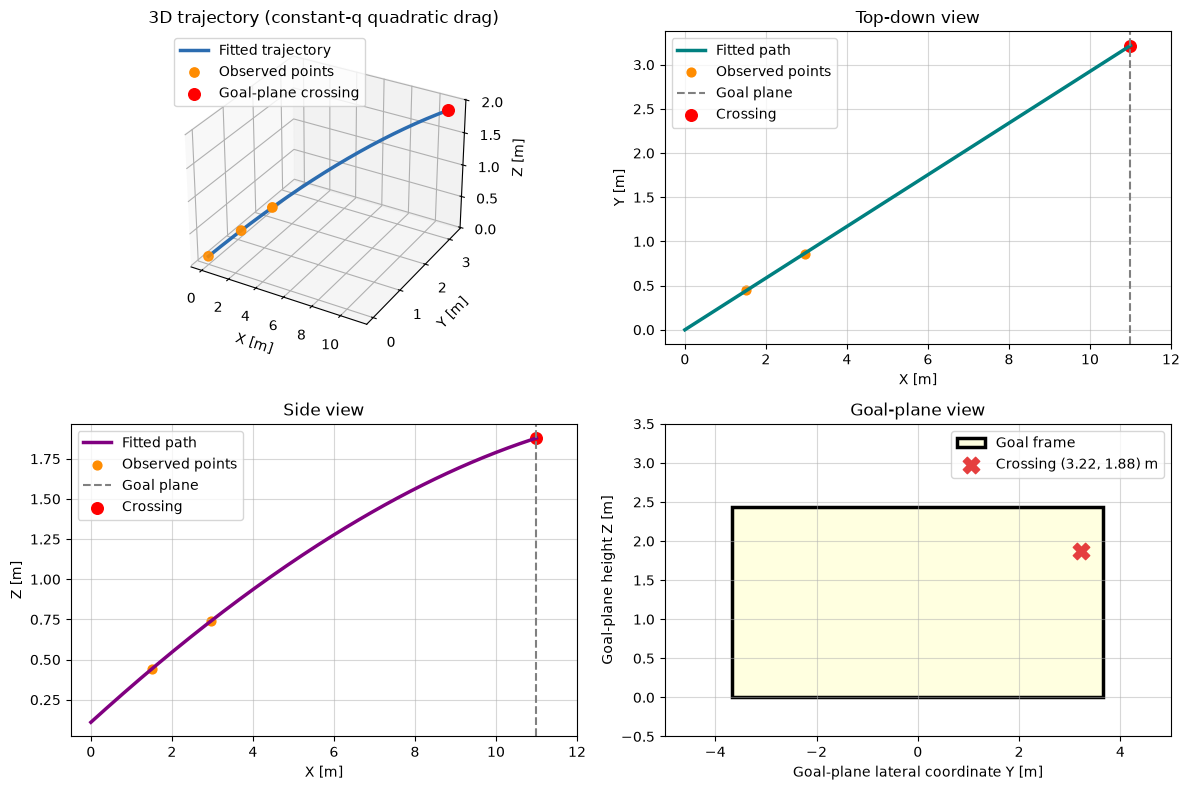

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.stats import chi2

# Constant-q quadratic drag: a_drag = -q*|v|*v.
goal_x = 11.0
goal_y_bounds = (-3.66, 3.66)
goal_z_bounds = (0.0, 2.44)
g = 9.81
r0 = np.array([0.0, 0.0, 0.11])
r1 = np.array([1.50, 0.45, 0.44])
r2 = np.array([2.96, 0.86, 0.74])
dt = 0.05
observation_times = np.array([dt, 2 * dt])
sigma_position = 0.005  # Assumed independent Gaussian coordinate standard deviation (m)


def quadratic_drag_ode(t, state, q):
    x, y, z, vx, vy, vz = state
    velocity = np.array([vx, vy, vz])
    speed = np.linalg.norm(velocity)
    acceleration = -q * speed * velocity + np.array([0.0, 0.0, -g])
    return [vx, vy, vz, *acceleration]


def integrate_observations(v0, q):
    sol = solve_ivp(
        lambda t, state: quadratic_drag_ode(t, state, q),
        (0.0, observation_times[-1]), np.concatenate((r0, v0)),
        t_eval=observation_times, max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success or sol.y.shape[1] != len(observation_times):
        raise RuntimeError(f"Observation integration failed: {sol.message}")
    return sol.y[:3, :].T


def fit_quadratic_drag(r1_observed, r2_observed):
    observed = np.vstack((r1_observed, r2_observed))
    v0_guess = (4 * r1_observed - r2_observed - 3 * r0) / (2 * dt)
    vx1 = (r1_observed[0] - r0[0]) / dt
    vx2 = (r2_observed[0] - r1_observed[0]) / dt
    path_length = 0.5 * (np.linalg.norm(r1_observed-r0) + np.linalg.norm(r2_observed-r1_observed))
    q_guess = np.log(vx1 / vx2) / path_length if vx1 > vx2 > 0 else 0.01
    q_guess = max(q_guess, 1e-5)

    def residual(parameters):
        return ((integrate_observations(parameters[:3], parameters[3]) - observed) / sigma_position).ravel()

    fit = least_squares(
        residual, np.concatenate((v0_guess, [q_guess])),
        bounds=(np.array([-np.inf, -np.inf, -np.inf, 1e-8]), np.full(4, np.inf)),
        x_scale="jac", max_nfev=100,
    )
    if not fit.success:
        raise RuntimeError(f"Quadratic-drag fit failed: {fit.message}")
    predicted = integrate_observations(fit.x[:3], fit.x[3])
    return fit.x[:3], fit.x[3], observed - predicted


def integrate_to_goal(v0, q):
    def goal_event(t, state):
        return state[0] - goal_x
    goal_event.terminal = True
    goal_event.direction = 1
    sol = solve_ivp(
        lambda t, state: quadratic_drag_ode(t, state, q),
        (0.0, 1.0), np.concatenate((r0, v0)), events=goal_event,
        max_step=0.002, rtol=1e-8, atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(f"Goal integration failed: {sol.message}")
    if len(sol.t_events[0]) == 0:
        raise RuntimeError("The fitted trajectory did not reach the goal plane.")
    t_goal = sol.t_events[0][0]
    impact_state = sol.y_events[0][0]
    path = np.column_stack((sol.t, sol.y.T))
    if not np.isclose(path[-1, 0], t_goal):
        path = np.vstack((path, np.concatenate(([t_goal], impact_state))))
    return t_goal, path, impact_state


v0_fit, q_fit, fit_residuals = fit_quadratic_drag(r1, r2)
t_goal, trajectory, impact_state = integrate_to_goal(v0_fit, q_fit)
x, y, z = trajectory[:, 1], trajectory[:, 2], trajectory[:, 3]
y_goal, z_goal = impact_state[1], impact_state[2]
fit_rmse = np.sqrt(np.mean(fit_residuals**2))
fit_chi2 = np.sum((fit_residuals / sigma_position) ** 2)
fit_dof = fit_residuals.size - 4
print("CONSTANT-q QUADRATIC-DRAG FIT")
print(f"Fitted launch velocity: ({v0_fit[0]:.4f}, {v0_fit[1]:.4f}, {v0_fit[2]:.4f}) m/s")
print(f"Fitted q: {q_fit:.6f} 1/m")
print(f"Observed - fitted position residuals (mm):\n{(1000 * fit_residuals).round(2)}")
print(f"Coordinate fit RMSE: {1000 * fit_rmse:.2f} mm (assumed sigma = {1000*sigma_position:.1f} mm)")
print(f"Noise-only fit diagnostic: chi-square={fit_chi2:.2f}, dof={fit_dof}, p={chi2.sf(fit_chi2, fit_dof):.4f}")
print(f"Goal-plane crossing: t={t_goal:.4f} s, y={y_goal:.3f} m, z={z_goal:.3f} m")
print("The fit and crossing are conditional on this constant-q model and the fixed initial position.")

fig = plt.figure(figsize=(12, 8))

ax1 = fig.add_subplot(221, projection="3d")
ax1.plot(x, y, z, color="#2B6CB0", linewidth=2.5, label="Fitted trajectory")
ax1.scatter([r0[0], r1[0], r2[0]], [r0[1], r1[1], r2[1]], [r0[2], r1[2], r2[2]], color="darkorange", s=45, label="Observed points")
ax1.scatter([goal_x], [y_goal], [z_goal], color="red", s=70, label="Goal-plane crossing")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
ax1.set_zlabel("Z [m]")
ax1.set_title("3D trajectory (constant-q quadratic drag)")
ax1.legend(loc="upper left")

ax2 = fig.add_subplot(222)
ax2.plot(x, y, color="#008080", linewidth=2.5, label="Fitted path")
ax2.scatter([r1[0], r2[0]], [r1[1], r2[1]], color="darkorange", s=40, label="Observed points")
ax2.axvline(goal_x, color="gray", linestyle="--", label="Goal plane")
ax2.scatter(goal_x, y_goal, color="red", s=70, label="Crossing")
ax2.set_xlim(-0.5, 12.0)
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
ax2.set_title("Top-down view")
ax2.grid(True, alpha=0.5)
ax2.legend()

ax3 = fig.add_subplot(223)
ax3.plot(x, z, color="purple", linewidth=2.5, label="Fitted path")
ax3.scatter([r1[0], r2[0]], [r1[2], r2[2]], color="darkorange", s=40, label="Observed points")
ax3.axvline(goal_x, color="gray", linestyle="--", label="Goal plane")
ax3.scatter(goal_x, z_goal, color="red", s=70, label="Crossing")
ax3.set_xlim(-0.5, 12.0)
ax3.set_xlabel("X [m]")
ax3.set_ylabel("Z [m]")
ax3.set_title("Side view")
ax3.grid(True, alpha=0.5)
ax3.legend()

ax4 = fig.add_subplot(224)
ax4.add_patch(Rectangle((goal_y_bounds[0], goal_z_bounds[0]), goal_y_bounds[1]-goal_y_bounds[0], goal_z_bounds[1]-goal_z_bounds[0], linewidth=2.5, edgecolor="black", facecolor="#FFFFE0", label="Goal frame", zorder=1))
ax4.scatter(y_goal, z_goal, color="#E53E3E", marker="X", s=140, zorder=4, label=f"Crossing ({y_goal:.2f}, {z_goal:.2f}) m")
ax4.set_xlim(-5.0, 5.0)
ax4.set_ylim(-0.5, 3.5)
ax4.set_xlabel("Goal-plane lateral coordinate Y [m]")
ax4.set_ylabel("Goal-plane height Z [m]")
ax4.set_title("Goal-plane view")
ax4.grid(True, alpha=0.5)
ax4.legend(loc="upper right")

plt.tight_layout()
plt.show()
